# Experiment 4: Rendering on Modest Hardware (Quantization, fp16, LCM, Offload)

Experiments 1 to 3 asked **"does the render keep the design?"**. This one asks **"what does it cost to run, and what do we lose when we make it cheaper?"**

I keep the pipeline from Experiment 1 (**Canny ControlNet + img2img, strength 0.6, 25 steps, 768×432**) and change only how it runs:

| Variant | What changes | Expected effect |
|---|---|---|
| **fp32** | Full precision (reference) | Most memory, slowest |
| **fp16** | Half precision weights | About half the memory, faster |
| **UNet 8-bit** | UNet linear layers in 8-bit (bitsandbytes LLM.int8) | Less memory, maybe slower |
| **UNet 4-bit** | UNet linear layers in 4-bit NF4 (bitsandbytes) | Least memory, maybe slower and less accurate |
| **fp16 + LCM-LoRA** | 8 steps instead of 25, guidance 1.0 | Much faster, some quality loss |
| **fp16 + CPU offload** | Parts of the model wait on the CPU until needed | Less GPU memory, slower |

In my thesis I used quantization for LLMs. Here I test whether the same idea works for an image model, where small errors can show up as visible color or detail changes.

**Measured for every variant**
- **Model memory** (GPU memory after loading) and **peak memory** during generation
- **Seconds per image** (after one warm-up run)
- **Drift from fp32**: ΔE and SSIM between the variant's image and the fp32 image with the same seed. This shows what the cheaper setting itself changed.
- **Design preservation** (as in Experiment 1): ΔE and edge recall against the original photo
- **CLIP score** against the prompt

## 1. Setup

In [1]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate peft bitsandbytes opencv-python

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2. Check the GPU (must print True and Tesla T4)

In [2]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu130 True Tesla T4


## 3. Upload the same room images

In [3]:
from google.colab import files
uploaded = files.upload()
images = list(uploaded)
print(images)

Saving living-room.jpg to living-room.jpg
Saving open-plan.jpg to open-plan.jpg
Saving room.jpg to room.jpg
['living-room.jpg', 'open-plan.jpg', 'room.jpg']


## 4. Helpers
- `load_variant(name)` builds the pipeline for one variant. Only one variant is in GPU memory at a time.
- For the quantized variants, only the **UNet** is quantized (it is about 85% of the weights). bitsandbytes quantizes **linear layers** (attention and feed-forward); convolution layers stay in fp16.

In [4]:
import gc, time, cv2, numpy as np, pandas as pd
from PIL import Image
from diffusers import (StableDiffusionControlNetImg2ImgPipeline, ControlNetModel,
                       UNet2DConditionModel, LCMScheduler)
from diffusers import BitsAndBytesConfig as DiffusersBnbConfig

MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CNET = "lllyasviel/sd-controlnet-canny"
prompt = "photorealistic interior render, light oak wooden floor, white walls, natural daylight"
negative = "blurry, distorted, low quality, deformed"
W, H = 768, 432
SEED, STEPS, STRENGTH = 42, 25, 0.6

VARIANTS = ["fp32", "fp16", "unet_8bit", "unet_4bit", "fp16_lcm", "fp16_offload"]

def free():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

def gb(x):
    return x / 1024**3

def load_variant(name):
    dtype = torch.float32 if name == "fp32" else torch.float16
    controlnet = ControlNetModel.from_pretrained(CNET, torch_dtype=dtype)
    kwargs = {}
    if name in ("unet_8bit", "unet_4bit"):
        q = (DiffusersBnbConfig(load_in_8bit=True) if name == "unet_8bit" else
             DiffusersBnbConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                bnb_4bit_compute_dtype=torch.float16))
        kwargs["unet"] = UNet2DConditionModel.from_pretrained(
            MODEL, subfolder="unet", quantization_config=q, torch_dtype=torch.float16)
    pipe = StableDiffusionControlNetImg2ImgPipeline.from_pretrained(
        MODEL, controlnet=controlnet, torch_dtype=dtype, safety_checker=None, **kwargs)
    if name == "fp16_offload":
        pipe.enable_model_cpu_offload()        # parts move to the GPU only when needed
    else:
        pipe.to("cuda")    # a quantized UNet is already on the GPU; diffusers leaves it as it is
    if name == "fp16_lcm":
        pipe.load_lora_weights("latent-consistency/lcm-lora-sdv1-5")
        pipe.scheduler = LCMScheduler.from_config(pipe.scheduler.config)
    pipe.set_progress_bar_config(disable=True)
    return pipe

def run(pipe, name, room, edges):
    lcm = name == "fp16_lcm"
    return pipe(prompt, negative_prompt=None if lcm else negative,
                image=room, control_image=edges, strength=STRENGTH,
                num_inference_steps=8 if lcm else STEPS,
                guidance_scale=1.0 if lcm else 7.5,
                generator=torch.manual_seed(SEED)).images[0]

def load_room(name):
    return Image.open(name).convert("RGB").resize((W, H))

def canny_map(room):
    e = cv2.Canny(np.array(room), 100, 200)
    return Image.fromarray(np.stack([e] * 3, axis=-1))

rooms = {n: load_room(n) for n in images}
edges = {n: canny_map(r) for n, r in rooms.items()}

## 5. Run every variant
For each variant: load it, measure model memory, do one warm-up run (not timed), then time each room and record peak memory.

This takes about 10 to 15 minutes on a T4. If a variant fails (for example a bitsandbytes version problem), the error is printed and the loop continues with the next one.

In [5]:
outputs, perf = {}, []
for name in VARIANTS:
    free()
    try:
        pipe = load_variant(name)
        torch.cuda.synchronize()
        model_mem = gb(torch.cuda.memory_allocated())
        run(pipe, name, rooms[images[0]], edges[images[0]])          # warm-up, not timed
        torch.cuda.reset_peak_memory_stats()
        times = []
        for n, room_name in enumerate(images, start=1):
            torch.cuda.synchronize(); t0 = time.time()
            img = run(pipe, name, rooms[room_name], edges[room_name])
            torch.cuda.synchronize(); times.append(time.time() - t0)
            outputs[(name, room_name)] = img
            img.save(f"exp4_{name}_{n}.jpg", quality=90)
        perf.append({"variant": name, "model memory (GB) ↓": model_mem,
                     "peak memory (GB) ↓": gb(torch.cuda.max_memory_allocated()),
                     "seconds / image ↓": np.mean(times)})
        print(f"{name:13s} ok  model {model_mem:.2f} GB  {np.mean(times):.1f} s/img")
    except Exception as e:
        print(f"{name:13s} FAILED: {type(e).__name__}: {e}")
    finally:
        pipe = None
        free()

perf_df = pd.DataFrame(perf).set_index("variant")
display(perf_df.round(2))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (26 outputs left out)

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet_img2img.StableDiffusionControlNetImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


fp16_offload  ok  model 0.01 GB  8.5 s/img


,model memory (GB) ↓,peak memory (GB) ↓,seconds / image ↓
variant,,,
fp32,5.35,6.38,23.34
fp16,2.70,3.50,6.08
unet_8bit,2.46,3.25,7.49
unet_4bit,2.34,3.13,6.17
fp16_lcm,2.84,3.61,1.41
fp16_offload,0.01,2.67,8.55


## 6. Look at the images
One row per room: **original | fp32 | fp16 | 8-bit | 4-bit | LCM | offload**. Offload should look the same as fp16 (only where the weights wait changes).

order: original | fp32 | fp16 | unet_8bit | unet_4bit | fp16_lcm | fp16_offload


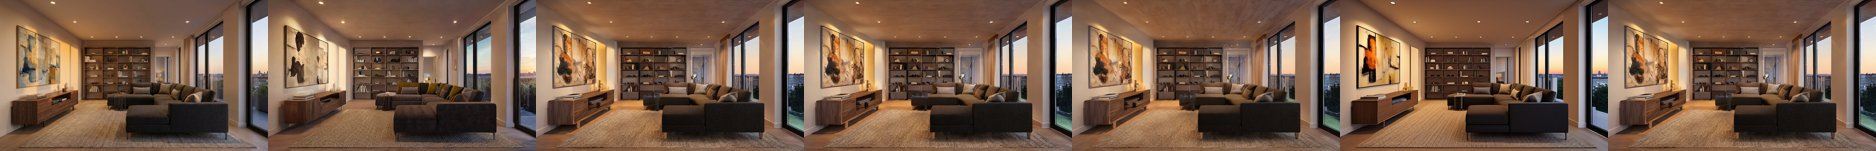

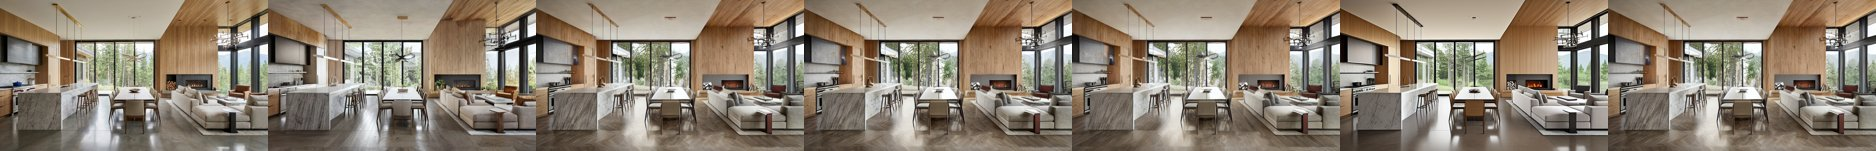

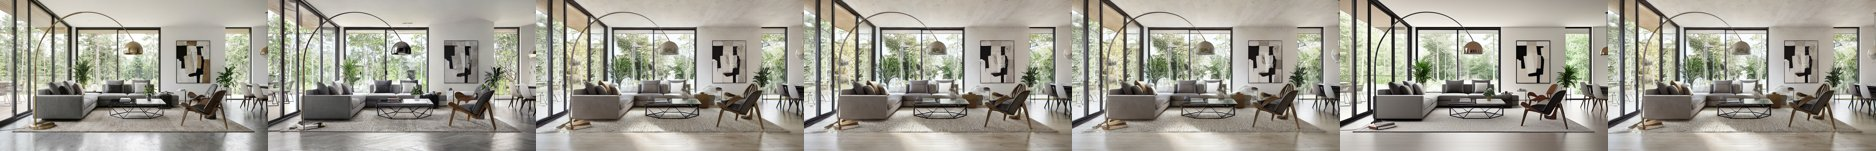

In [7]:
from IPython.display import Image as IPImage, display
import io

def show_row(imgs, scale=0.35):
    w, h = int(W * scale), int(H * scale)
    row = Image.new("RGB", (w * len(imgs), h), "white")
    for i, im in enumerate(imgs):
        if im is not None:
            row.paste(im.convert("RGB").resize((w, h)), (i * w, 0))
    buf = io.BytesIO(); row.save(buf, format="JPEG", quality=85)
    display(IPImage(data=buf.getvalue()))          # JPEG is much faster to show than PNG
    return row

done = [v for v in VARIANTS if (v, images[0]) in outputs]
print("order: original |", " | ".join(done))
for n, room_name in enumerate(images, start=1):
    row = show_row([rooms[room_name]] + [outputs.get((v, room_name)) for v in done])
    row.save(f"exp4_comparison_{n}.jpg", quality=90)

## 7. Measure quality
- **Drift from fp32**: how different is each image from the fp32 image (same seed)? fp16 should be almost the same; 4-bit and LCM may drift more.
- **Preservation**: ΔE and edge recall against the original photo, as in Experiment 1.

In [8]:
from skimage.metrics import structural_similarity as ssim
from skimage.color import rgb2lab, deltaE_ciede2000
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda")
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
def clip_score(img):
    inputs = clip_proc(text=[prompt], images=img, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        out = clip(**inputs)
    return float((out.image_embeds @ out.text_embeds.T).item() * 100)

def gray(a): return cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
def delta_e(a, b): return deltaE_ciede2000(rgb2lab(a), rgb2lab(b)).mean()
def edge_recall(orig, rend):
    e_o = cv2.Canny(orig, 100, 200) > 0
    e_r = cv2.dilate((cv2.Canny(rend, 100, 200) > 0).astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    return (e_o & e_r).sum() / max(e_o.sum(), 1)

rows = []
for room_name in images:
    orig = np.array(rooms[room_name])
    ref = outputs.get(("fp32", room_name))
    for v in done:
        img = np.array(outputs[(v, room_name)])
        r = {"variant": v,
             "ΔE vs fp32 ↓": delta_e(np.array(ref), img) if ref is not None else np.nan,
             "SSIM vs fp32 ↑": ssim(gray(np.array(ref)), gray(img)) if ref is not None else np.nan,
             "ΔE vs original ↓": delta_e(orig, img),
             "Edge recall ↑": edge_recall(orig, img),
             "CLIP score ↑": clip_score(outputs[(v, room_name)])}
        rows.append(r)

quality_df = pd.DataFrame(rows).groupby("variant").mean().reindex(done)
summary = perf_df.join(quality_df).round(3)
display(summary)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

,model memory (GB) ↓,peak memory (GB) ↓,seconds / image ↓,ΔE vs fp32 ↓,SSIM vs fp32 ↑,ΔE vs original ↓,Edge recall ↑,CLIP score ↑
variant,,,,,,,,
fp32,5.348,6.380,23.344,0.000,1.000,8.703,0.935,29.112
fp16,2.705,3.498,6.079,10.166,0.508,8.944,0.939,29.333
unet_8bit,2.455,3.249,7.486,10.253,0.505,9.031,0.937,29.229
unet_4bit,2.339,3.131,6.167,10.135,0.505,8.906,0.931,29.804
fp16_lcm,2.840,3.614,1.411,10.015,0.551,8.540,0.950,30.344
fp16_offload,0.009,2.675,8.549,10.166,0.508,8.944,0.939,29.333


In [12]:
rows = []
for room_name in images:
    ref = np.array(outputs[("fp16", room_name)])
    for v in done:
        img = np.array(outputs[(v, room_name)])
        rows.append({"variant": v, "ΔE vs fp16 ↓": delta_e(ref, img), "SSIM vs fp16 ↑": ssim(gray(ref), gray(img))})
display(pd.DataFrame(rows).groupby("variant").mean().reindex(done).round(3))

,ΔE vs fp16 ↓,SSIM vs fp16 ↑
variant,,
fp32,10.166,0.508
fp16,0.000,1.000
unet_8bit,1.572,0.960
unet_4bit,2.071,0.936
fp16_lcm,8.856,0.583
fp16_offload,0.000,1.000


## 8. Memory vs speed
Each point is one variant. Bottom left is best (less memory, faster). The label shows the drift from fp32.

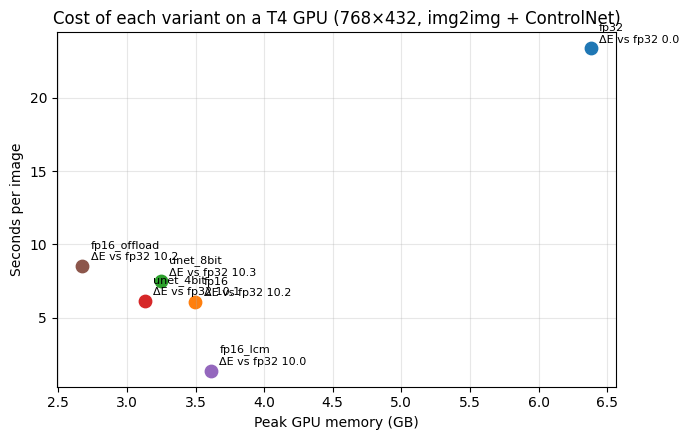

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4.5))
for v, r in summary.iterrows():
    ax.scatter(r["peak memory (GB) ↓"], r["seconds / image ↓"], s=80)
    ax.annotate(f"{v}\nΔE vs fp32 {r['ΔE vs fp32 ↓']:.1f}", (r["peak memory (GB) ↓"], r["seconds / image ↓"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("Peak GPU memory (GB)"); ax.set_ylabel("Seconds per image")
ax.set_title("Cost of each variant on a T4 GPU (768×432, img2img + ControlNet)")
ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig("exp4_memory_vs_speed.png", dpi=150); plt.show()

**What I saw.**
- **fp32 → fp16:** Half the memory (6.4 → 3.5 GB) and 3.8× faster (23.3 → 6.1 s), with the same design preservation (ΔE to the original 8.7 vs 8.9). fp16 reproduced Experiment 1.
- **My first quality metric was wrong.** All fp16-based variants were equally far from fp32 (ΔE ≈ 10), even plain fp16: small rounding differences grow over 25 steps into a different but valid image. So I compared against fp16 instead.
- **8-bit and 4-bit UNet:** Almost the same image as fp16 (ΔE 1.6 and 2.1), but only 7–11% less memory; 8-bit was also 23% slower. Only the UNet's linear layers are quantized; the rest stays in fp16.
- **LCM-LoRA:** 4.3× faster than fp16 (1.4 s) with no loss in design preservation (ΔE 8.5, edge recall 0.95). A different image, not a worse one.
- **CPU offload:** The lowest GPU memory (2.7 GB peak), 40% slower, and exactly the same image as fp16.

**Result.** Always use fp16. For speed, LCM-LoRA; for a small GPU, CPU offload. Quantization is not worth it for SD 1.5: unlike my thesis LLMs, most of its memory is not in linear layers.

**Limits.** One GPU (T4), three rooms, one seed. Newer GPUs with int8/fp8 support may give different speed results.

## 9. Download the results

In [13]:
summary.to_csv("exp4_metrics.csv")
!zip -q exp4_results.zip exp4_*.jpg exp4_*.png exp4_metrics.csv
files.download("exp4_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>